# Session 14 — Loan Application Exploratory Data Analysis

Generate 1,500 fictional NBFC loan applications with NumPy seed 42. Perform univariate, bivariate and multivariate analysis, and save the requested CSV and PNG outputs.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

OUTPUT_DIR = Path.cwd()


## 1. Generate the loan application dataset

In [2]:
rng = np.random.default_rng(42)
n = 1500

age = rng.integers(21, 61, n)
monthly_income = rng.integers(15000, 150001, n)
loan_amount = rng.integers(50000, 800001, n)
tenure = rng.choice([12, 24, 36, 48, 60], n)
employment = rng.choice(["Salaried", "Self-employed", "Business"], n)
city_tier = rng.integers(1, 4, n)
credit_score = rng.integers(550, 851, n)

default_probability = (
    0.05
    + 0.15 * (credit_score < 650)
    + 0.10 * (loan_amount > 10 * monthly_income)
)
defaulted = (rng.random(n) < default_probability).astype(int)

df = pd.DataFrame({
    "age": age,
    "monthly_income_inr": monthly_income,
    "loan_amount_inr": loan_amount,
    "tenure_months": tenure,
    "employment": employment,
    "city_tier": city_tier,
    "credit_score": credit_score,
    "defaulted": defaulted
})

df.to_csv(OUTPUT_DIR / "loan_applications.csv", index=False)
print(df.head())
print("Dataset shape:", df.shape)


   age  monthly_income_inr  loan_amount_inr  tenure_months     employment  \
0   24               86514           633526             48  Self-employed   
1   51               50147           553891             36       Business   
2   47               45917           747450             60  Self-employed   
3   38               58536           770441             48  Self-employed   
4   38               95658           578679             12  Self-employed   

   city_tier  credit_score  defaulted  
0          3           684          0  
1          1           555          1  
2          3           752          0  
3          2           686          0  
4          3           782          0  
Dataset shape: (1500, 8)


## 2. Univariate analysis

In [3]:
numeric_cols = [
    "age", "monthly_income_inr", "loan_amount_inr",
    "tenure_months", "city_tier", "credit_score", "defaulted"
]
print("Numeric column descriptions:")
print(df[numeric_cols].describe())

print("\\nNormalized value counts for categorical columns:")
for col in ["employment"]:
    print(f"\\n{col}:")
    print(df[col].value_counts(normalize=True))


Numeric column descriptions:
               age  monthly_income_inr  loan_amount_inr  tenure_months  \
count  1500.000000         1500.000000      1500.000000    1500.000000   
mean     40.685333        82161.156667    419911.874667      35.944000   
std      11.564406        39192.099007    214768.254383      16.995924   
min      21.000000        15070.000000     50426.000000      12.000000   
25%      31.000000        47904.250000    236027.500000      24.000000   
50%      41.000000        80114.500000    408162.000000      36.000000   
75%      51.000000       116426.500000    609673.500000      48.000000   
max      60.000000       149922.000000    799825.000000      60.000000   

         city_tier  credit_score    defaulted  
count  1500.000000   1500.000000  1500.000000  
mean      1.976667    698.843333     0.125333  
std       0.809460     85.242159     0.331207  
min       1.000000    550.000000     0.000000  
25%       1.000000    625.000000     0.000000  
50%       2.0000

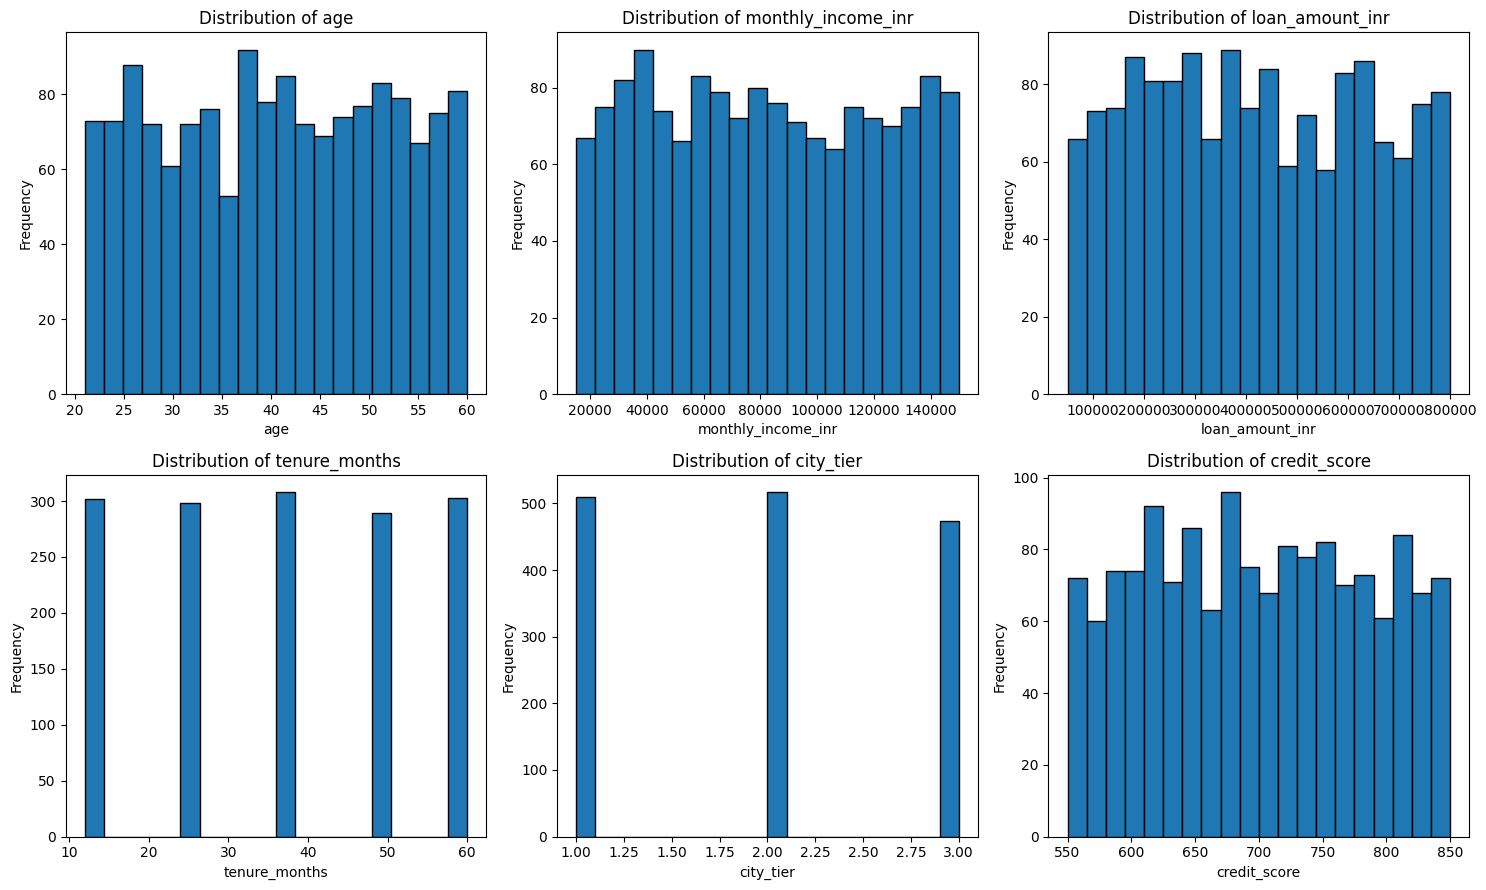

In [4]:
hist_cols = [
    "age", "monthly_income_inr", "loan_amount_inr",
    "tenure_months", "city_tier", "credit_score"
]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, col in zip(axes.flat, hist_cols):
    ax.hist(df[col], bins=20, edgecolor="black")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "loan_numeric.png", dpi=150, bbox_inches="tight")
plt.show()


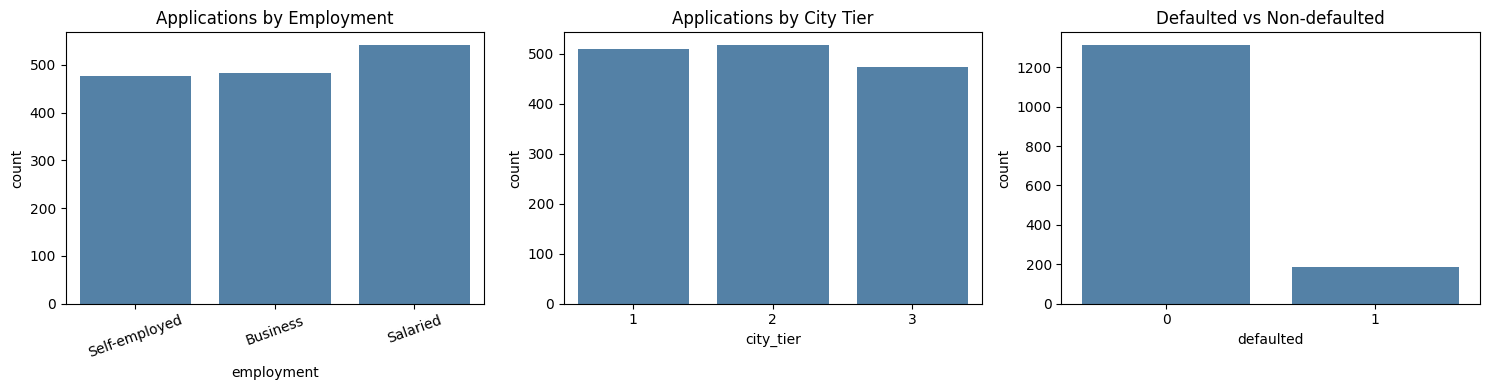

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x="employment", color="steelblue", ax=axes[0])
axes[0].set_title("Applications by Employment")
axes[0].tick_params(axis="x", rotation=20)

sns.countplot(data=df, x="city_tier", color="steelblue", ax=axes[1])
axes[1].set_title("Applications by City Tier")

sns.countplot(data=df, x="defaulted", color="steelblue", ax=axes[2])
axes[2].set_title("Defaulted vs Non-defaulted")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "loan_categorical.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Bivariate analysis

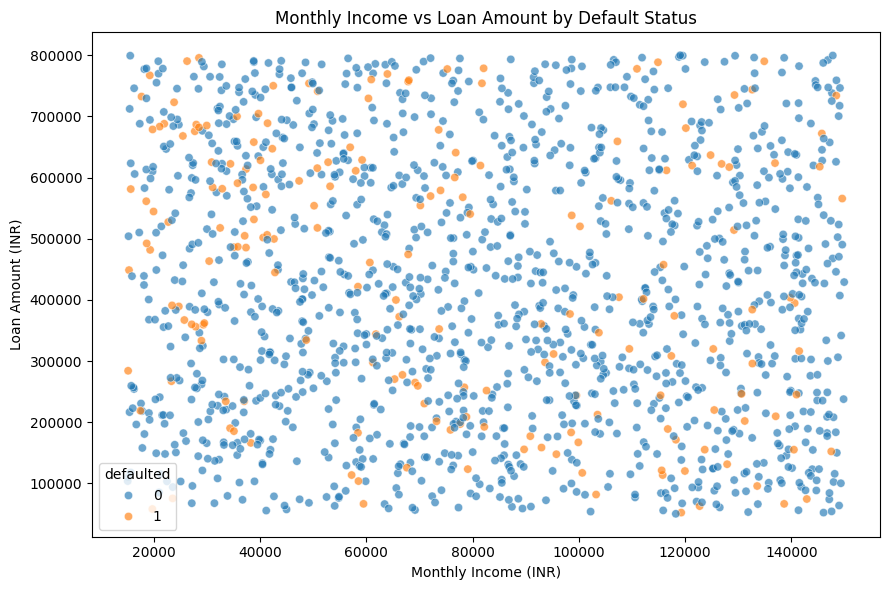

Correlation of every numeric column with defaulted:
credit_score         -0.153388
monthly_income_inr   -0.082756
age                   0.000376
city_tier             0.028333
loan_amount_inr       0.038867
tenure_months         0.052444
defaulted             1.000000
Name: defaulted, dtype: float64


In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=df, x="monthly_income_inr", y="loan_amount_inr",
    hue="defaulted", alpha=0.65, ax=ax
)
ax.set_title("Monthly Income vs Loan Amount by Default Status")
ax.set_xlabel("Monthly Income (INR)")
ax.set_ylabel("Loan Amount (INR)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "loan_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlation of every numeric column with defaulted:")
print(df.select_dtypes(include="number").corr(numeric_only=True)["defaulted"].sort_values())


In [7]:
employment_rates = df.groupby("employment")["defaulted"].mean()
city_rates = df.groupby("city_tier")["defaulted"].mean()

print("Mean default rate by employment:")
print(employment_rates)
print("\\nMean default rate by city tier:")
print(city_rates)

default_rates = pd.concat([
    employment_rates.rename("default_rate").reset_index()
        .rename(columns={"employment": "category"}).assign(group="employment"),
    city_rates.rename("default_rate").reset_index()
        .rename(columns={"city_tier": "category"}).assign(group="city_tier")
], ignore_index=True)[["group", "category", "default_rate"]]

default_rates.to_csv(OUTPUT_DIR / "default_rates.csv", index=False)


Mean default rate by employment:
employment
Business         0.113872
Salaried         0.149723
Self-employed    0.109244
Name: defaulted, dtype: float64
\nMean default rate by city tier:
city_tier
1    0.111984
2    0.129594
3    0.135021
Name: defaulted, dtype: float64


## 4. Multivariate analysis

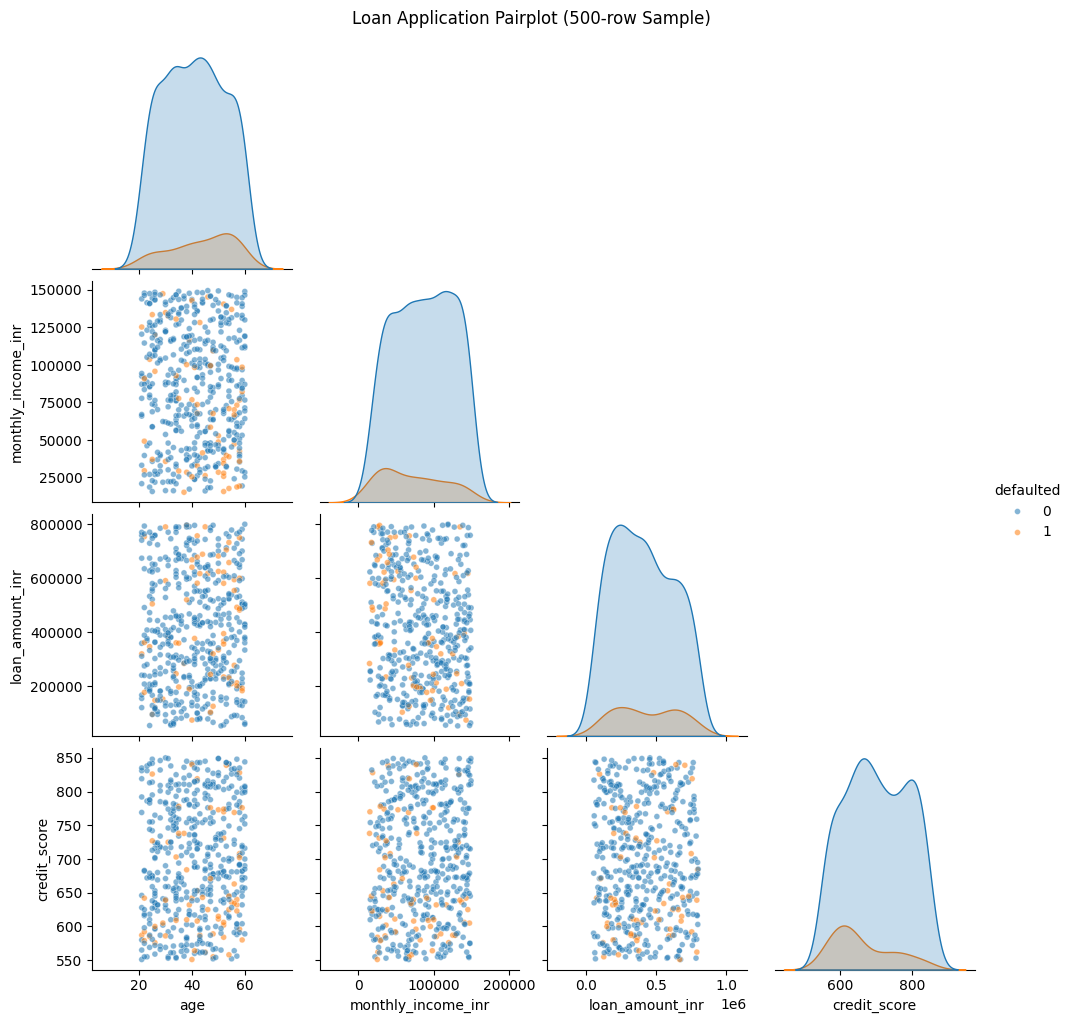

In [8]:
pair_sample = df[
    ["age", "monthly_income_inr", "loan_amount_inr", "credit_score", "defaulted"]
].sample(n=500, random_state=42)

g = sns.pairplot(
    pair_sample,
    vars=["age", "monthly_income_inr", "loan_amount_inr", "credit_score"],
    hue="defaulted",
    corner=True,
    plot_kws={"alpha": 0.55, "s": 18}
)
g.fig.suptitle("Loan Application Pairplot (500-row Sample)", y=1.02)
g.savefig(OUTPUT_DIR / "loan_pairplot.png", dpi=120, bbox_inches="tight")
plt.show()


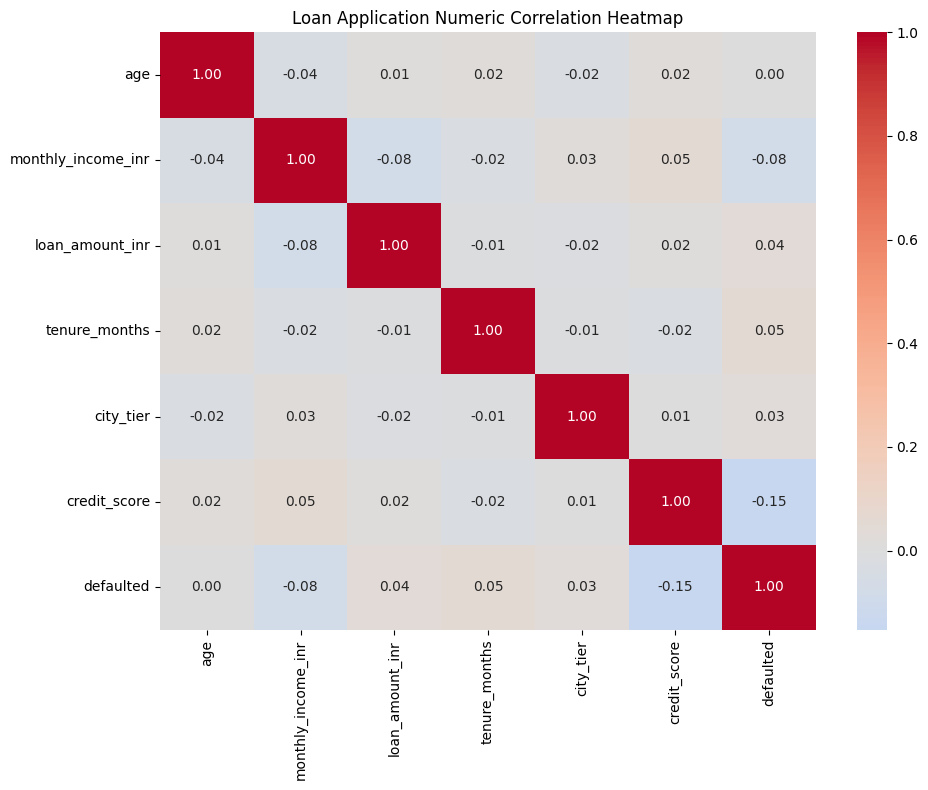

In [9]:
corr = df.select_dtypes(include="number").corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Loan Application Numeric Correlation Heatmap")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "loan_corr_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


## Evidence-based EDA findings

In [10]:
overall_default_rate = df["defaulted"].mean()
low_score_default_rate = df.loc[df["credit_score"] < 650, "defaulted"].mean()
high_loan_income_default_rate = df.loc[
    df["loan_amount_inr"] > 10 * df["monthly_income_inr"], "defaulted"
].mean()
avg_income_defaulted = df.loc[df["defaulted"] == 1, "monthly_income_inr"].mean()
avg_income_nondefaulted = df.loc[df["defaulted"] == 0, "monthly_income_inr"].mean()
employment_rates = df.groupby("employment")["defaulted"].mean()

eda_findings = pd.DataFrame([
    {
        "finding": "Overall default incidence",
        "evidence": f"Default rate = {overall_default_rate:.3f} ({int(df['defaulted'].sum())} of {len(df)} applications)."
    },
    {
        "finding": "Credit score and default",
        "evidence": f"Default rate for credit scores below 650 = {low_score_default_rate:.3f}."
    },
    {
        "finding": "Loan-to-income risk",
        "evidence": f"Default rate where loan exceeds 10 times monthly income = {high_loan_income_default_rate:.3f}."
    },
    {
        "finding": "Income comparison",
        "evidence": f"Mean monthly income: defaulters ₹{avg_income_defaulted:.0f}; non-defaulters ₹{avg_income_nondefaulted:.0f}."
    },
    {
        "finding": "Employment segment",
        "evidence": f"Highest employment default rate = {employment_rates.max():.3f} for {employment_rates.idxmax()}."
    }
])

print(eda_findings)
eda_findings.to_csv(OUTPUT_DIR / "loan_eda_findings.csv", index=False)


                     finding  \
0  Overall default incidence   
1   Credit score and default   
2        Loan-to-income risk   
3          Income comparison   
4         Employment segment   

                                            evidence  
0   Default rate = 0.125 (188 of 1500 applications).  
1  Default rate for credit scores below 650 = 0.222.  
2  Default rate where loan exceeds 10 times month...  
3  Mean monthly income: defaulters ₹73596; non-de...  
4  Highest employment default rate = 0.150 for Sa...  


## Verify generated deliverables

In [11]:
required_files = [
    "loan_applications.csv",
    "loan_numeric.png",
    "loan_categorical.png",
    "loan_scatter.png",
    "default_rates.csv",
    "loan_pairplot.png",
    "loan_corr_heatmap.png",
    "loan_eda_findings.csv"
]
for filename in required_files:
    print(filename, "exists:", Path(filename).exists())


loan_applications.csv exists: True
loan_numeric.png exists: True
loan_categorical.png exists: True
loan_scatter.png exists: True
default_rates.csv exists: True
loan_pairplot.png exists: True
loan_corr_heatmap.png exists: True
loan_eda_findings.csv exists: True
